In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv("IMDB_Dataset.csv")

print("Dataset Shape:", data.shape)
print(data.head())

Dataset Shape: (50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [3]:
X = data['review'].astype(str)
y = data['sentiment'].map({'positive': 1, 'negative': 0})

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

X_train = pad_sequences(X_train, maxlen=200, padding='post')
X_test = pad_sequences(X_test, maxlen=200, padding='post')

In [6]:
model = Sequential([
    Embedding(10000, 32),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

In [7]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [8]:
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 74ms/step - accuracy: 0.5666 - loss: 0.6695 - val_accuracy: 0.5696 - val_loss: 0.6581
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 74ms/step - accuracy: 0.6063 - loss: 0.6271 - val_accuracy: 0.6217 - val_loss: 0.6086
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.7216 - loss: 0.5223 - val_accuracy: 0.8245 - val_loss: 0.4372
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.7208 - loss: 0.5672 - val_accuracy: 0.7501 - val_loss: 0.5599
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 72ms/step - accuracy: 0.7972 - loss: 0.4841 - val_accuracy: 0.7673 - val_loss: 0.5260


In [9]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7683 - loss: 0.5256
Test Accuracy: 76.83 %


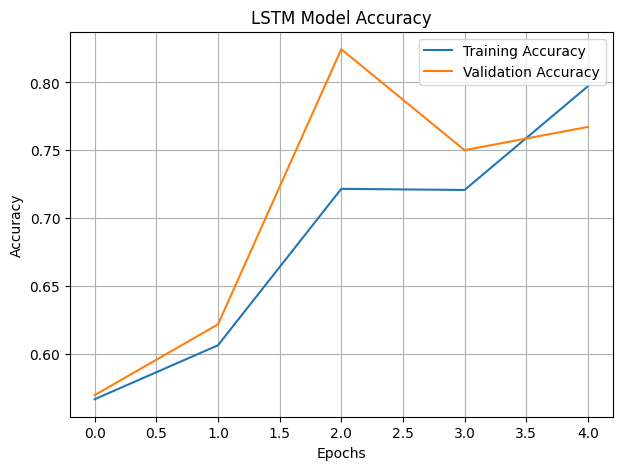

In [10]:
plt.figure(figsize=(7, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("LSTM Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [11]:
predictions = model.predict(X_test[:5])

print("\nActual vs Predicted Sentiment")

for i in range(5):
    actual = "Positive" if y_test.iloc[i] == 1 else "Negative"
    predicted = "Positive" if predictions[i][0] >= 0.5 else "Negative"

    print("\nReview:", i + 1)
    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", predicted)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 640ms/step

Actual vs Predicted Sentiment

Review: 1
Actual Sentiment: Positive
Predicted Sentiment: Positive

Review: 2
Actual Sentiment: Positive
Predicted Sentiment: Positive

Review: 3
Actual Sentiment: Negative
Predicted Sentiment: Negative

Review: 4
Actual Sentiment: Positive
Predicted Sentiment: Positive

Review: 5
Actual Sentiment: Negative
Predicted Sentiment: Positive
